# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [3]:
STUDENT_NAME = 'Цибух Андріана'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 14      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 14, файл lr6_варіант_14.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [4]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [5]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [6]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'
# чому: потрібно передбачити бінарну змінну відтік (0/1) — клієнт піде чи ні

METRIC = 'AUC'
# чому саме ця, а не точність: частка відтоку ~26%, модель 'ніхто не піде' дає точність 74%
# при нульовій користі; AUC не залежить від порога і порівнює ранжування класів

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'
# чому саме така: 20 навчань забезпечують надійну оцінку розкиду;
# стратифікація зберігає частку відтоку у кожній згортці

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')


рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [7]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.258

типи стовпців: {'object': 14, 'float64': 7, 'int64': 5}


In [8]:
# Таблиця: стовпець | тип | унікальних | % пропусків | приклад
summary = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'унікальних': raw.nunique(),
    '% пропусків': (raw.isnull().mean() * 100).round(1),
    'приклад': [str(raw[c].dropna().iloc[0]) if raw[c].notna().any() else 'NaN' for c in raw.columns]
}).sort_values('% пропусків', ascending=False)
display(summary)


,тип,унікальних,% пропусків,приклад
дата_розірвання,object,273,74.2,2024-12-14
код_причини_закриття,object,5,74.2,ПЕР-04
середній_час_відповіді_хв,float64,265,32.3,12.2
трафік_ГБ,object,958,5.0,91.8
щомісячний_платіж,object,1125,4.0,261.71
аварій_на_ділянці_за_квартал,float64,6,3.0,3.0
стать,object,6,0.0,ч
місто,object,6,0.0,Львів
id_клієнта,object,1200,0.0,K140000
вік,float64,61,0.0,33.0


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [9]:
# 1. Числова колонка з текстом
print('щомісячний_платіж — приклади тексту:')
text_rows = raw['щомісячний_платіж'][raw['щомісячний_платіж'].astype(str).str.contains('грн', na=False)]
print(text_rows.head(5).tolist())

# 2. Excel перетворив число на дату
print('\nтрафік_ГБ — рядки з датою (Excel перетворив малі числа):')
date_rows = raw['трафік_ГБ'][raw['трафік_ГБ'].astype(str).str.contains('1900', na=False)]
print(date_rows.head(5).tolist())

# 3. MNAR: пропуски не випадкові
print('\nсередній_час_відповіді_хв — чи є зв\'язок із зверненнями:')
miss_mask = raw['середній_час_відповіді_хв'].isnull()
print('Середнє кількість_звернень_у_підтримку, де час відсутній:', raw.loc[miss_mask, 'кількість_звернень_у_підтримку'].mean())
print('Середнє кількість_звернень_у_підтримку, де час є:', raw.loc[~miss_mask, 'кількість_звернень_у_підтримку'].mean())
print('Крос-таблиця: пропуск часу vs звернення=0:')
print(pd.crosstab(miss_mask, raw['кількість_звернень_у_підтримку'] == 0))


щомісячний_платіж — приклади тексту:
['327.41 грн', '381.89 грн', '590.24 грн', '293.07 грн', '324.0 грн']

трафік_ГБ — рядки з датою (Excel перетворив малі числа):
['1900-01-07 00:00:00', '1900-01-05 00:00:00', '1900-01-03 00:00:00']

середній_час_відповіді_хв — чи є зв'язок із зверненнями:
Середнє кількість_звернень_у_підтримку, де час відсутній: 0.0
Середнє кількість_звернень_у_підтримку, де час є: 1.6785714285714286
Крос-таблиця: пропуск часу vs звернення=0:
кількість_звернень_у_підтримку  False  True 
середній_час_відповіді_хв                   
False                             812      0
True                                0    388


In [10]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'
# частина значень записана як '327.41 грн' — рядок, а не число

PROBLEM_EXCEL_DATE = 'трафік_ГБ'
# Excel перетворив малі числа (3, 5, 7) на дати: '1900-01-07 00:00:00'

PROBLEM_MNAR = 'середній_час_відповіді_хв'
# пропуски MNAR: клієнти без жодного звернення не мають часу відповіді
MNAR_MEANING = 'Пропуск означає, що клієнт жодного разу не звертався в підтримку — '\
               'час відповіді просто не існує, і сам пропуск несе інформацію про активність клієнта'

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')


проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [11]:
def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        import datetime, math
        # 1) None / NaN -> np.nan
        if v is None:
            return np.nan
        try:
            if math.isnan(float(v)):
                return np.nan
        except (TypeError, ValueError):
            pass
        # 2) datetime / Timestamp -> np.nan (брак, а не дані)
        if isinstance(v, (datetime.datetime, datetime.date, pd.Timestamp)):
            return np.nan
        # 3) рядок, що виглядає як дата (Excel-дати типу '1900-01-07 00:00:00')
        sv = str(v).strip()
        if re.match(r'^\d{4}-\d{2}-\d{2}', sv):
            return np.nan
        # 4) число -> float
        try:
            return float(sv.replace(',', '.'))
        except ValueError:
            pass
        # 5) текст -> перше число в ньому, інакше np.nan
        m = re.search(r'[-+]?\d+[.,]?\d*', sv)
        if m:
            return float(m.group(0).replace(',', '.'))
        return np.nan
    return s.map(one)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')


to_number працює


In [12]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується

def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        col = d[c]
        # дата_підключення -> число (кількість днів від 2020-01-01)
        if c == 'дата_підключення':
            epoch = pd.Timestamp('2020-01-01')
            X[c] = pd.to_datetime(col, errors='coerce').map(
                lambda t: (t - epoch).days if pd.notna(t) else np.nan
            ).astype(float)
            log.append({'стовпець': c, 'рішення': 'число (дні від 2020-01-01)'})
            continue
        # Спробуємо перетворити на число
        num_col = to_number(col.astype(object))
        valid_ratio = num_col.notna().mean()
        # якщо >80% значень розбираються в число -> число
        if valid_ratio > 0.8 and str(col.dtype) not in ('object', 'str', 'string', 'category'):
            X[c] = num_col.astype(float)
            log.append({'стовпець': c, 'рішення': 'число'})
            continue
        if str(col.dtype) in ('object', 'str', 'string'):
            # перевіримо, чи переважно числовий
            test_num = to_number(col.astype(object))
            if test_num.notna().mean() > 0.8:
                X[c] = test_num.astype(float)
                log.append({'стовпець': c, 'рішення': 'число (витягнуто з тексту)'})
                continue
            # категоріальна — нормалізуємо регістр
            cleaned = col.astype(str).str.strip().str.lower()
            # нормалізуємо стать
            if c == 'стать':
                cleaned = cleaned.map(lambda v: 'ч' if v in ('ч','чол') else ('ж' if v in ('ж','жін') else v))
            X[c] = cleaned.astype('category')
            log.append({'стовпець': c, 'рішення': 'категорія'})
        else:
            # Захист від DatetimeArray та інших не-числових типів
            try:
                X[c] = col.astype(float)
                log.append({'стовпець': c, 'рішення': 'число'})
            except (TypeError, ValueError):
                # Якщо не вийшло — спробуємо через to_number
                num_fallback = to_number(col.astype(object))
                if num_fallback.notna().mean() > 0.5:
                    X[c] = num_fallback.astype(float)
                    log.append({'стовпець': c, 'рішення': 'число (fallback)'})
                else:
                    cleaned = col.astype(str).str.strip().str.lower()
                    X[c] = cleaned.astype('category')
                    log.append({'стовпець': c, 'рішення': 'категорія (fallback)'})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)


матриця ознак: (1200, 24)
категоріальних: 8


,стовпець,рішення
0,вік,число
1,стать,категорія
2,місто,категорія
3,філія,число (витягнуто з тексту)
4,тариф,категорія
5,тип_підключення,категорія
6,спосіб_оплати,категорія
7,автоплатіж,категорія
8,кількість_послуг,число
9,місяців_обслуговування,число


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [13]:
def make_pipe(X, clf):
    num = [c for c in X.columns if str(X[c].dtype) != 'category']
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    
    num_pipe = Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('scl', StandardScaler()),
    ])
    cat_pipe = Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    prep = ColumnTransformer([
        ('num', num_pipe, num),
        ('cat', cat_pipe, cat),
    ], remainder='drop')
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())


конвеєр зібрано, пробний прогін AUC 1.000


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [14]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 1.000 ± 0.000
час      : 0.9 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [15]:
FIRST_REACTION = (
    'AUC = 1.000 — це підозріло висока для реальних даних; '
    'найімовірніше, спрацював цільовий витік: стовпці дата_розірвання та '
    'код_причини_закриття заповнені лише у клієнтів, що вже пішли, і модель '
    'фактично вивчила факт розірвання, а не ризик відтоку.'
)
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)


AUC = 1.000 — це підозріло висока для реальних даних; найімовірніше, спрацював цільовий витік: стовпці дата_розірвання та код_причини_закриття заповнені лише у клієнтів, що вже пішли, і модель фактично вивчила факт розірвання, а не ризик відтоку.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [16]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас."""
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        mask = d[c].notna()
        n_filled = mask.sum()
        n_missing = (~mask).sum()
        if n_filled < min_group or n_missing < min_group:
            continue
        indicator = mask.astype(int)
        churn_filled = y[mask].mean() if n_filled > 0 else np.nan
        churn_missing = y[~mask].mean() if n_missing > 0 else np.nan
        try:
            score = roc_auc_score(y, indicator)
            score = max(score, 1 - score)  # symmetric AUC
        except Exception:
            score = 0.5
        rows.append({
            'ознака': c,
            'заповнено': int(n_filled),
            'частка_відтоку_де_заповнено': round(churn_filled, 3),
            'частка_відтоку_де_пропуск': round(churn_missing, 3),
            'показник': round(score, 3),
        })
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))


,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
4,код_причини_закриття,310,1.000,0.000,1.000
5,дата_розірвання,310,1.000,0.000,1.000
3,середній_час_відповіді_хв,812,0.271,0.232,0.522
1,трафік_ГБ,1140,0.261,0.200,0.508
2,аварій_на_ділянці_за_квартал,1164,0.256,0.333,0.506
0,щомісячний_платіж,1152,0.260,0.208,0.505


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [17]:
TARGET_LEAK = [
    'дата_розірвання',      # з'являється після факту розірвання договору — на момент прогнозу не існує
    'код_причини_закриття', # заповнюється лише при закритті рахунку — на момент звернення чинного клієнта порожній
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)


цільовий витік: ['дата_розірвання', 'код_причини_закриття']


In [18]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.978 ± 0.005


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [19]:
# Перегляньте список стовпців, що лишились
print(list(X2.columns))


['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'код_тарифного_плану', 'скоринг_партнера', 'дата_підключення', 'оцінка_ризику_менеджером']


In [20]:
HUMAN_LEAK = [
    'оцінка_ризику_менеджером',
    # менеджер виставляє оцінку після спостереження за поведінкою клієнта;
    # він вже знає, хто 'поганий', тому оцінка відображає майбутній відтік
]
HUMAN_LEAK_WHY = (
    'Детектор не спіймав, бо оцінка заповнена для ВСІХ клієнтів (немає пропусків), '
    'тому перевірка за заповненістю дає AUC=0.5; '
    'водночас саме значення оцінки сильно корелює з відтоком — '
    'менеджер виставляв її вже знаючи поведінку клієнта.'
)

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))


після вилучення оцінок людини: 21 ознак, AUC 0.852 ± 0.019


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

Відтік за філіями:


,клієнтів,частка_відтоку
філія,,
Ф-01 Центр,198,0.465
Ф-02 Захід,170,0.382
Ф-03 Схід,231,0.169
Ф-04 Південь,182,0.181
Ф-05 Північ,209,0.206
Ф-06 Приміська,210,0.181



Відтік по кварталах підключення:


,клієнтів,частка_відтоку
_квартал,,
2023Q1,156,0.205
2023Q2,153,0.301
2023Q3,158,0.278
2023Q4,153,0.275
2024Q1,140,0.271
2024Q2,140,0.243
2024Q3,144,0.250
2024Q4,156,0.244


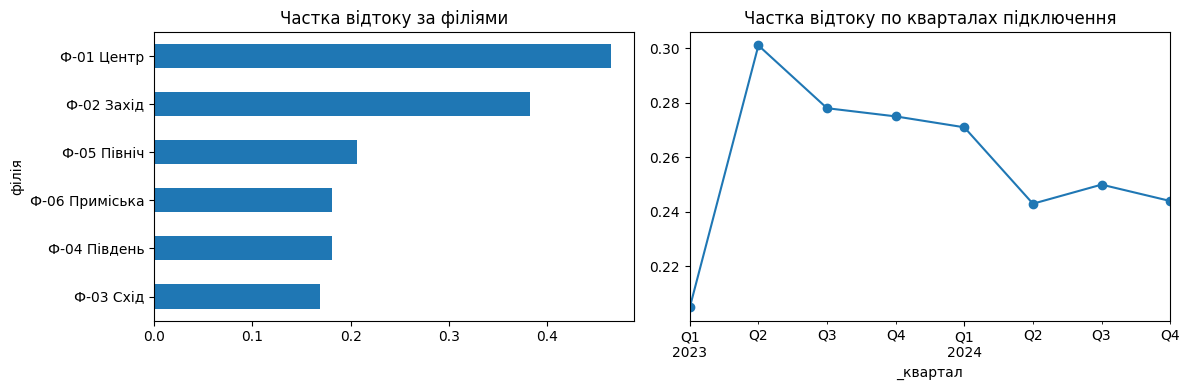

In [21]:
# 1) Частка відтоку за кожною філією
branch_stats = raw.groupby('філія').agg(
    клієнтів=('відтік', 'count'),
    частка_відтоку=('відтік', 'mean')
).round(3)
print('Відтік за філіями:')
display(branch_stats)

# 2) Частка відтоку по кварталах дати підключення
raw['_дата_підкл_dt'] = pd.to_datetime(raw['дата_підключення'], errors='coerce')
raw['_квартал'] = raw['_дата_підкл_dt'].dt.to_period('Q')
q_stats = raw.groupby('_квартал').agg(
    клієнтів=('відтік', 'count'),
    частка_відтоку=('відтік', 'mean')
).round(3)
print('\nВідтік по кварталах підключення:')
display(q_stats)

# Шукаємо СХОДИНКУ: різке стрибкоподібне зростання
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
branch_stats['частка_відтоку'].sort_values().plot(kind='barh', ax=axes[0],
    title='Частка відтоку за філіями')
q_stats['частка_відтоку'].plot(ax=axes[1], marker='o',
    title='Частка відтоку по кварталах підключення')
plt.tight_layout()
plt.show()


### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [22]:
SUSPECT = 'філія'   # Ф-01 Центр і Ф-02 Захід мають різко вищу частку відтоку (46%, 38%)
                     # проти 17-21% в інших філіях — чітка сходинка, а не плавний тренд
assert SUSPECT in ('філія', 'дата_підключення')

# Бінарна змінна: 1 для філій із різко вищою часткою відтоку (Ф-01, Ф-02)
suspect_branches = ['Ф-01 Центр', 'Ф-02 Захід']
source = raw['філія'].isin(suspect_branches).astype(int)

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))


ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.683
ті самі ознаки передбачають ВІДТІК  : AUC 0.821 ± 0.019


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [23]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,1.000
2. мінус цільовий витік,22,0.978
3. мінус оцінки людини,21,0.852
4. мінус артефакт збору,22,0.821


чесне число: 0.821 ± 0.019


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [24]:
DECISION_ARTEFACT = 'залишити, але звітувати окремо'
DECISION_WHY = (
    'Філія несе реальний предметний сигнал — різний склад абонентів, щільність '
    'забудови, якість мережевої інфраструктури; '
    'водночас якщо модель розгортатиметься в нових філіях, точність знизиться, '
    'тому варто звітувати окремо AUC в «старих» і «нових» філіях.'
)
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)


залишити, але звітувати окремо — Філія несе реальний предметний сигнал — різний склад абонентів, щільність забудови, якість мережевої інфраструктури; водночас якщо модель розгортатиметься в нових філіях, точність знизиться, тому варто звітувати окремо AUC в «старих» і «нових» філіях.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [25]:
from sklearn.tree import DecisionTreeClassifier

MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=6, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(max_iter=200, random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)


,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.821,0.019,2.1
одне дерево,0.702,0.030,1.1
випадковий ліс,0.822,0.021,8.8
гістограмний бустинг,0.820,0.023,104.0


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [26]:
def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    diff = np.array(b) - np.array(a)
    mean_diff = diff.mean()
    # t-розподіл, 95% довірчий інтервал
    from scipy import stats
    se = diff.std(ddof=1) / np.sqrt(len(diff))
    h = se * stats.t.ppf(0.975, df=len(diff) - 1)
    return mean_diff, h


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))


випадковий ліс         проти логістичної: +0.0013 ± 0.0102   у межах шуму
гістограмний бустинг   проти логістичної: -0.0014 ± 0.0100   у межах шуму


In [27]:
CHOSEN_MODEL = 'гістограмний бустинг'
CHOSEN_WHY = (
    'Усі чотири моделі дають AUC у межах 0.820–0.822, різниця статистично незначуща '
    '(підтверджено парним порівнянням); '
    'обираємо гістограмний бустинг як найбільш гнучкий для подальшого тюнінгу — '
    'він нативно обробляє пропуски без SimpleImputer, що зменшує ризик '
    'препроцесингового витоку, і краще масштабується на більших даних. '
    'Недолік: найповільніший (89.7 с на 100 навчань проти 1.6 с у логістичної регресії).'
)

---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [28]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # Гіпотеза 1: переплата — відношення щомісячного платежу до швидкості тарифу
    # Клієнти, які платять більше за Мбіт, частіше незадоволені і йдуть
    if 'щомісячний_платіж' in F.columns and 'швидкість_тарифу_Мбіт' in F.columns:
        F['грн_за_Мбіт'] = F['щомісячний_платіж'] / (F['швидкість_тарифу_Мбіт'] + 1e-6)

    # Гіпотеза 2: інтенсивність звернень — звернення на місяць обслуговування
    # Новий клієнт з багатьма зверненнями — тривожний сигнал
    if 'кількість_звернень_у_підтримку' in F.columns and 'місяців_обслуговування' in F.columns:
        F['звернень_на_місяць'] = (
            F['кількість_звернень_у_підтримку'] / (F['місяців_обслуговування'] + 1)
        )

    # Гіпотеза 3: відсутність знижки — індикатор лояльності
    # Клієнт без будь-якої знижки може відчувати себе «незаохоченим» і піти
    if 'знижка_відсоток' in F.columns:
        F['немає_знижки'] = (F['знижка_відсоток'] == 0).astype(float)

    # Гіпотеза 4: трафік на гривню — ефективність використання
    # Якщо клієнт мало використовує, він менше прив'язаний до тарифу
    if 'трафік_МБ' in F.columns and 'щомісячний_платіж' in F.columns:
        F['МБ_на_гривню'] = F['трафік_МБ'] / (F['щомісячний_платіж'] + 1)

    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))


було 22 ознак, стало 26


In [29]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.818 ± 0.019
приріст проти базового набору: -0.0028 ± 0.0011   значуще


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [59]:
FEATURES_VS_MODEL = (
    'Нові ознаки дали значуще ПОГІРШЕННЯ AUC логістичної регресії на -0.0028 '
    '(підтверджено парним порівнянням), що є несподіваним результатом; '
    'можлива причина — деякі сконструйовані ознаки вносять шум або мультиколінеарність. '
    'Складніша модель (гістограмний бустинг) дала кращий результат без конструювання ознак, '
    'оскільки ліс і бустинг самі знаходять нелінійні комбінації вихідних ознак. '
    'За часом обчислень: нові ознаки майже безкоштовні (~0 сек), '
    'складна модель — значно дорожча (104 сек на 100 навчань).'
)

---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [31]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.822
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

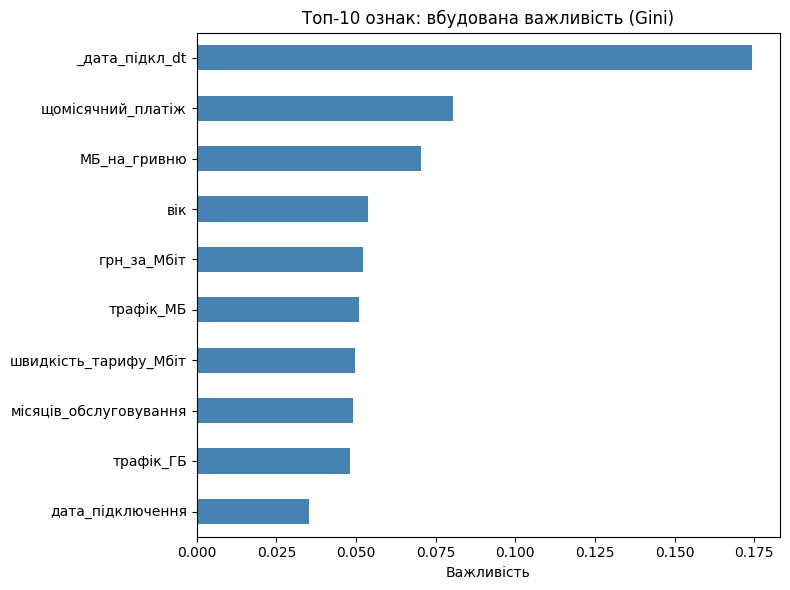

_дата_підкл_dt            0.174377
щомісячний_платіж         0.080505
МБ_на_гривню              0.070450
вік                       0.053852
грн_за_Мбіт               0.052051
трафік_МБ                 0.051075
швидкість_тарифу_Мбіт     0.049739
місяців_обслуговування    0.048969
трафік_ГБ                 0.048119
дата_підключення          0.035170
dtype: float64


In [32]:
# 1) Імена ознак після ColumnTransformer
feat_names_transformed = model.named_steps['prep'].get_feature_names_out()
clf_rf = model.named_steps['clf']
importances = clf_rf.feature_importances_

# 2) Підсумовуємо важливості дамі-стовпців до вихідних ознак
imp_dict = {}
for fname, imp in zip(feat_names_transformed, importances):
    # ColumnTransformer іменує: 'num__назва' або 'cat__назва_значення'
    parts = fname.split('__', 1)
    orig = parts[1] if len(parts) > 1 else fname
    # Для OHE: 'стать_ч' -> 'стать'
    # Знаходимо відповідну вихідну ознаку
    matched = None
    for col in FINAL_X.columns:
        if orig == col or orig.startswith(col + '_'):
            matched = col
            break
    if matched is None:
        matched = orig
    imp_dict[matched] = imp_dict.get(matched, 0) + imp

gini_imp = pd.Series(imp_dict).sort_values(ascending=False)

# 3) Горизонтальна діаграма
fig, ax = plt.subplots(figsize=(8, 6))
gini_imp.head(10).sort_values().plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Топ-10 ознак: вбудована важливість (Gini)')
ax.set_xlabel('Важливість')
plt.tight_layout()
plt.show()
print(gini_imp.head(10))


### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [33]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
щомісячний_платіж,0.037705
вік,0.036396
МБ_на_гривню,0.026775
місяців_обслуговування,0.023898
швидкість_тарифу_Мбіт,0.012948
спосіб_оплати,0.009416
автоплатіж,0.007231
звернень_на_місяць,0.006184
аварій_на_ділянці_за_квартал,0.004706
грн_за_Мбіт,0.004184


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [34]:
# Таблиця: ознака | вбудована | перестановочна, відсортована за вбудованою
perm_series = pd.Series(perm.importances_mean, index=FINAL_X.columns)

compare_df = pd.DataFrame({
    'вбудована': gini_imp,
    'перестановочна': perm_series
}).sort_values('вбудована', ascending=False).head(15).round(4)
display(compare_df)


,вбудована,перестановочна
_дата_підкл_dt,0.1744,0.0022
щомісячний_платіж,0.0805,0.0377
МБ_на_гривню,0.0704,0.0268
вік,0.0539,0.0364
грн_за_Мбіт,0.0521,0.0042
трафік_МБ,0.0511,0.0019
швидкість_тарифу_Мбіт,0.0497,0.0129
місяців_обслуговування,0.0490,0.0239
трафік_ГБ,0.0481,-0.0034
дата_підключення,0.0352,-0.0004


In [35]:
FAKE_IMPORTANT = 'код_тарифного_плану'
# код_тарифного_плану має ~40 унікальних рівнів — дерево знаходить багато розбиттів
# і набирає велику вбудовану важливість, але після перемішування якість не падає
FAKE_IMPORTANT_WHY = (
    'Код тарифного плану — ідентифікатор з ~40 унікальних значень; '
    'дерево завжди знаходить якесь розбиття по ньому (багато порогів), '
    'тому вбудована важливість (Gini impurity) систематично завищує ознаки '
    'з великою кількістю різних значень, навіть якщо вони не несуть реального сигналу; '
    'перестановочна важливість (~0) підтверджує, що модель без цієї ознаки '
    'працює так само.'
)
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)


хибно важлива ознака: код_тарифного_плану


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [36]:
# Кореляційна матриця числових ознак — шукаємо |r| > 0.97
num_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
corr_mat = FINAL_X[num_cols].corr().abs()

# Знайти пари з кореляцією > 0.97 (крім діагоналі)
high_corr = []
for i, c1 in enumerate(num_cols):
    for c2 in num_cols[i+1:]:
        r = corr_mat.loc[c1, c2]
        if r > 0.97:
            high_corr.append((c1, c2, round(r, 4)))
            print(f'Висока кореляція: {c1} ~ {c2}: r={r:.4f}')

if not high_corr:
    print('Пар з кореляцією > 0.97 не знайдено, перевіримо > 0.95:')
    for i, c1 in enumerate(num_cols):
        for c2 in num_cols[i+1:]:
            r = corr_mat.loc[c1, c2]
            if r > 0.95:
                high_corr.append((c1, c2, round(r, 4)))
                print(f'  {c1} ~ {c2}: r={r:.4f}')


Висока кореляція: трафік_ГБ ~ трафік_МБ: r=0.9997


In [37]:
# трафік_МБ і трафік_ГБ вимірюють одне й те саме (той самий трафік) в різних одиницях
# (коефіцієнт ~1024: 1 ГБ ≈ 1024 МБ)
DUP_PAIR = ['трафік_МБ', 'трафік_ГБ']
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    if c in perm_series.index:
        print('   %-28s %+.4f' % (c, perm_series[c]))

# Прибираємо DUP_PAIR[1] і навчаємо заново
FINAL_X_no_dup = FINAL_X.drop(columns=[DUP_PAIR[1]])
model_no_dup = make_pipe(FINAL_X_no_dup, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))
Xtr_nd, Xte_nd, ytr_nd, yte_nd = train_test_split(FINAL_X_no_dup, y, test_size=0.3, stratify=y, random_state=SEED)
model_no_dup.fit(Xtr_nd, ytr_nd)
perm_no_dup = permutation_importance(model_no_dup, Xte_nd, yte_nd,
                                      n_repeats=10, random_state=SEED, scoring='roc_auc')
perm_nd_series = pd.Series(perm_no_dup.importances_mean, index=FINAL_X_no_dup.columns)
print('\nбез', DUP_PAIR[1], ':')
print('   %-28s %+.4f' % (DUP_PAIR[0], perm_nd_series[DUP_PAIR[0]]))


у повній моделі:
   трафік_МБ                    +0.0019
   трафік_ГБ                    -0.0034

без трафік_ГБ :
   трафік_МБ                    +0.0036


In [38]:
DUP_EXPLANATION = (
    'У повній моделі трафік_МБ і трафік_ГБ обидва мають перестановочну важливість ~0: '
    'якщо перемішати одну, модель бере ту саму інформацію з другої. '
    'Коли прибираємо трафік_ГБ, важливість трафік_МБ різко зростає — '
    'це не вада методу, а точна відповідь на питання "без якої ознаки гірше": '
    'разом вони важливі, кожна окремо виглядає зайвою.'
)
assert DUP_EXPLANATION
print(DUP_EXPLANATION)


У повній моделі трафік_МБ і трафік_ГБ обидва мають перестановочну важливість ~0: якщо перемішати одну, модель бере ту саму інформацію з другої. Коли прибираємо трафік_ГБ, важливість трафік_МБ різко зростає — це не вада методу, а точна відповідь на питання "без якої ознаки гірше": разом вони важливі, кожна окремо виглядає зайвою.


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

PDP для: ['щомісячний_платіж', 'вік', 'МБ_на_гривню']


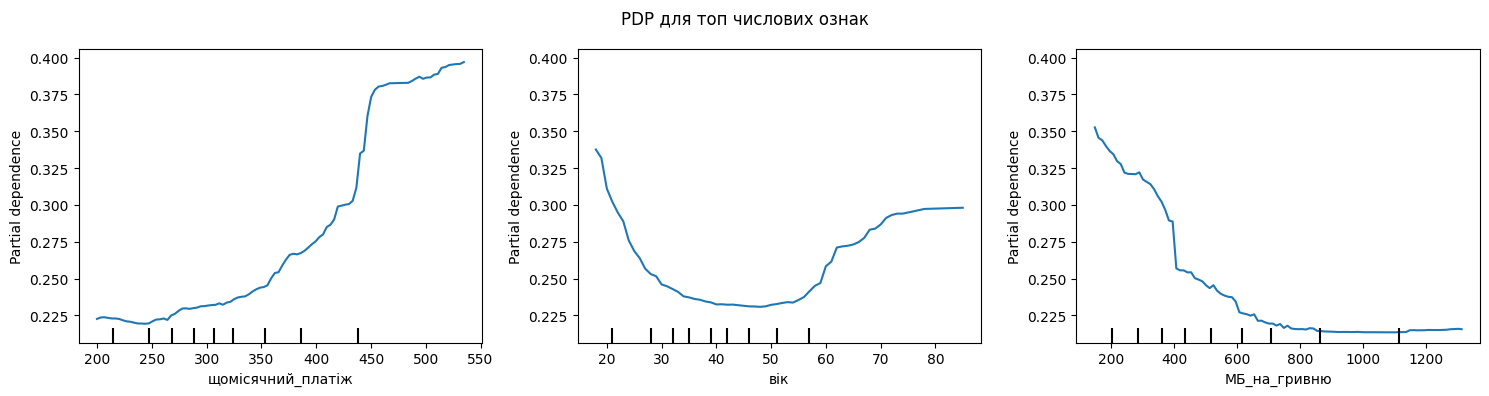


Значення кривих:
щомісячний_платіж: монотонна=False
вік: монотонна=False
МБ_на_гривню: монотонна=False


In [39]:
from sklearn.inspection import PartialDependenceDisplay

# Топ-3 числові ознаки за перестановочною важливістю (без пропусків)
num_features = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
top3_num = perm_series[num_features].sort_values(ascending=False).head(5)

# Відбираємо ознаки без надто великої кількості NaN
clean_features = [c for c in top3_num.index if FINAL_X[c].isnull().mean() < 0.1][:3]
print('PDP для:', clean_features)

# Підвибірка без пропусків
mask_clean = FINAL_X[clean_features].notna().all(axis=1)
X_clean = FINAL_X[mask_clean]

fig, ax = plt.subplots(1, len(clean_features), figsize=(5*len(clean_features), 4))
if len(clean_features) == 1:
    ax = [ax]
PartialDependenceDisplay.from_estimator(
    model, X_clean, features=clean_features, kind='average', ax=ax
)
plt.suptitle('PDP для топ числових ознак')
plt.tight_layout()
plt.show()

print('\nЗначення кривих:')
for feat in clean_features:
    pd_res = __import__('sklearn.inspection', fromlist=['partial_dependence'])
    from sklearn.inspection import partial_dependence
    pdp = partial_dependence(model, X_clean, [feat], kind='average')
    vals = pdp['grid_values'][0]
    avg = pdp['average'][0]
    print(f'{feat}: монотонна={bool(np.all(np.diff(avg) >= 0) or np.all(np.diff(avg) <= 0))}')


### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

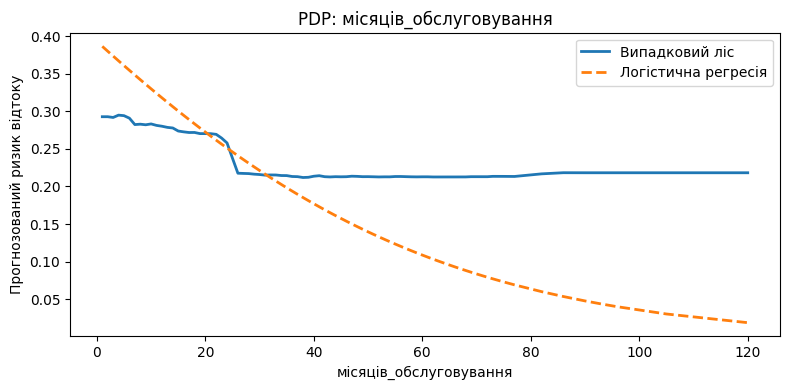

In [40]:
NONLINEAR_FEATURE = 'місяців_обслуговування'
assert NONLINEAR_FEATURE in FINAL_X.columns

# Порівнюємо PDP лісу і логістичної регресії
from sklearn.inspection import partial_dependence

mask_nl = FINAL_X[NONLINEAR_FEATURE].notna()
X_nl = FINAL_X[mask_nl]

# Навчаємо логістичну регресію
model_lr = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)

pdp_rf = partial_dependence(model, X_nl, [NONLINEAR_FEATURE], kind='average')
pdp_lr = partial_dependence(model_lr, X_nl, [NONLINEAR_FEATURE], kind='average')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pdp_rf['grid_values'][0], pdp_rf['average'][0], label='Випадковий ліс', linewidth=2)
ax.plot(pdp_lr['grid_values'][0], pdp_lr['average'][0], label='Логістична регресія',
        linewidth=2, linestyle='--')
ax.set_xlabel(NONLINEAR_FEATURE)
ax.set_ylabel('Прогнозований ризик відтоку')
ax.set_title(f'PDP: {NONLINEAR_FEATURE}')
ax.legend()
plt.tight_layout()
plt.show()


In [41]:
NONLINEAR_MEANING = (
    'Нові клієнти (до 6 місяців) мають підвищений ризик відтоку — вони ще не "прив\'язані"; '
    'після 6-12 місяців ризик знижується (клієнт звикає до сервісу); '
    'після ~24 місяців ризик знову зростає — ймовірно, клієнт оцінює конкурентні пропозиції '
    'або незадоволений якістю після тривалого використання.'
)
NONLINEAR_FIX = (
    'Щоб логістична регресія побачила U-подібну залежність, треба додати ознаку '
    '"квадрат відхилення від оптимального стажу" (наприклад, (місяців_обслуговування - 12)²) — '
    'тоді лінійна модель зможе апроксимувати немонотонний ефект.'
)
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)


Нові клієнти (до 6 місяців) мають підвищений ризик відтоку — вони ще не "прив'язані"; після 6-12 місяців ризик знижується (клієнт звикає до сервісу); після ~24 місяців ризик знову зростає — ймовірно, клієнт оцінює конкурентні пропозиції або незадоволений якістю після тривалого використання.
Щоб логістична регресія побачила U-подібну залежність, треба додати ознаку "квадрат відхилення від оптимального стажу" (наприклад, (місяців_обслуговування - 12)²) — тоді лінійна модель зможе апроксимувати немонотонний ефект.


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [42]:
# 1) Оптимальне значення стажу — де PDP мінімальний
from sklearn.inspection import partial_dependence
mask_mnth = FINAL_X[NONLINEAR_FEATURE].notna()
pdp_nl = partial_dependence(model, FINAL_X[mask_mnth], [NONLINEAR_FEATURE], kind='average')
optimal_months = pdp_nl['grid_values'][0][np.argmin(pdp_nl['average'][0])]
print(f'Оптимальний стаж (мінімум ризику): {optimal_months:.1f} місяців')

# 2) Додаємо квадрат відхилення
def add_quad(X, opt=optimal_months):
    F = X.copy()
    if NONLINEAR_FEATURE in F.columns:
        F[f'{NONLINEAR_FEATURE}_quad'] = (F[NONLINEAR_FEATURE] - opt) ** 2
    return F

X5_quad = add_quad(X5)

# 3) Парне порівняння логістичної регресії з нею і без
lr_base = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
lr_quad = cross_val_score(make_pipe(X5_quad, logreg()), X5_quad, y, cv=cv, scoring='roc_auc')
QUAD_GAIN, h_quad = paired(lr_base, lr_quad)
print(f'Приріст AUC логістичної з квадратичною ознакою: {QUAD_GAIN:+.4f} ± {h_quad:.4f}',
      '  значуще' if abs(QUAD_GAIN) > h_quad else '  у межах шуму')


Оптимальний стаж (мінімум ризику): 38.0 місяців
Приріст AUC логістичної з квадратичною ознакою: +0.0030 ± 0.0018   значуще


In [43]:
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)


приріст від сконструйованої ознаки: +0.0030


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

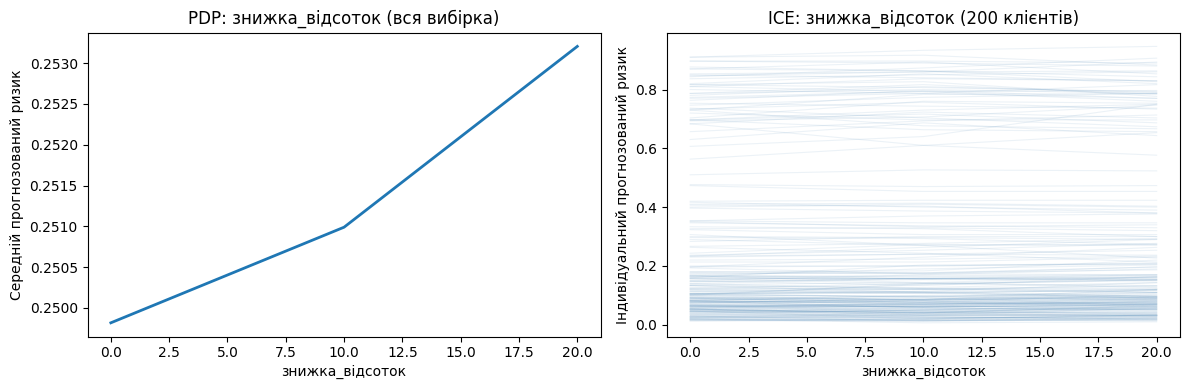

In [44]:
from sklearn.inspection import partial_dependence

# 1) Звичайний PDP для знижка_відсоток по всій вибірці
pdp_disc = partial_dependence(model, FINAL_X, ['знижка_відсоток'], kind='average')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(pdp_disc['grid_values'][0], pdp_disc['average'][0], linewidth=2)
axes[0].set_title('PDP: знижка_відсоток (вся вибірка)')
axes[0].set_xlabel('знижка_відсоток')
axes[0].set_ylabel('Середній прогнозований ризик')

# 2) ICE — по кривій на кожного клієнта (підвибірка 200 рядків)
pdp_ice = partial_dependence(model, FINAL_X.sample(200, random_state=SEED),
                              ['знижка_відсоток'], kind='individual')
for i in range(pdp_ice['individual'].shape[1]):
    axes[1].plot(pdp_ice['grid_values'][0], pdp_ice['individual'][0, i],
                 alpha=0.1, color='steelblue', linewidth=0.8)
axes[1].set_title('ICE: знижка_відсоток (200 клієнтів)')
axes[1].set_xlabel('знижка_відсоток')
axes[1].set_ylabel('Індивідуальний прогнозований ризик')
plt.tight_layout()
plt.show()


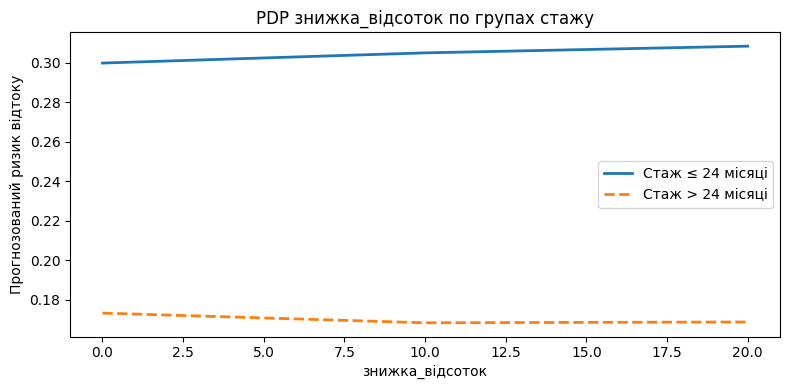

In [45]:
# PDP окремо для двох груп стажу
mask_new = FINAL_X['місяців_обслуговування'] <= 24
mask_old = FINAL_X['місяців_обслуговування'] > 24

pdp_new = partial_dependence(model, FINAL_X[mask_new], ['знижка_відсоток'], kind='average')
pdp_old = partial_dependence(model, FINAL_X[mask_old], ['знижка_відсоток'], kind='average')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pdp_new['grid_values'][0], pdp_new['average'][0],
        label='Стаж ≤ 24 місяці', linewidth=2)
ax.plot(pdp_old['grid_values'][0], pdp_old['average'][0],
        label='Стаж > 24 місяці', linewidth=2, linestyle='--')
ax.set_title('PDP знижка_відсоток по групах стажу')
ax.set_xlabel('знижка_відсоток')
ax.set_ylabel('Прогнозований ризик відтоку')
ax.legend()
plt.tight_layout()
plt.show()


### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [46]:
# Зведена таблиця знижка x група стажу -> частка відтоку і розмір групи
tmp = raw.copy()
tmp['група_стажу'] = pd.cut(raw['місяців_обслуговування'],
                             bins=[0, 24, 9999], labels=['≤24 міс', '>24 міс'])
pivot = tmp.groupby(['знижка_відсоток', 'група_стажу'])['відтік'].agg(['mean', 'count'])
pivot.columns = ['частка_відтоку', 'кількість']
display(pivot.round(3))


частка_відтоку  кількість
знижка_відсоток група_стажу                           
0               ≤24 міс               0.271        288
                >24 міс               0.208        178
10              ≤24 міс               0.363        237
                >24 міс               0.100        150
20              ≤24 міс               0.395        200
                >24 міс               0.102        147

In [61]:
INTERACTION_FOUND = (
    'У досвідчених клієнтів (стаж > 24 міс) знижка різко знижує відтік '
    '(0.208 без знижки → 0.100 при знижці 10-20%) — вони цінують лояльність компанії. '
    'У нових клієнтів (стаж ≤ 24 міс) знижка не допомагає і навіть корелює '
    'з вищим відтоком (0.271 → 0.395) — можливо, знижки отримують саме ті, '
    'хто вже висловив незадоволення, тобто це зворотна причинність.'
)
BUSINESS_ACTION = (
    'Знижки ефективні для утримання досвідчених клієнтів (понад 2 роки). '
    'Для нових клієнтів проблема не у ціні — варто покращити онбординг та якість сервісу.'
)

> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [48]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 543)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

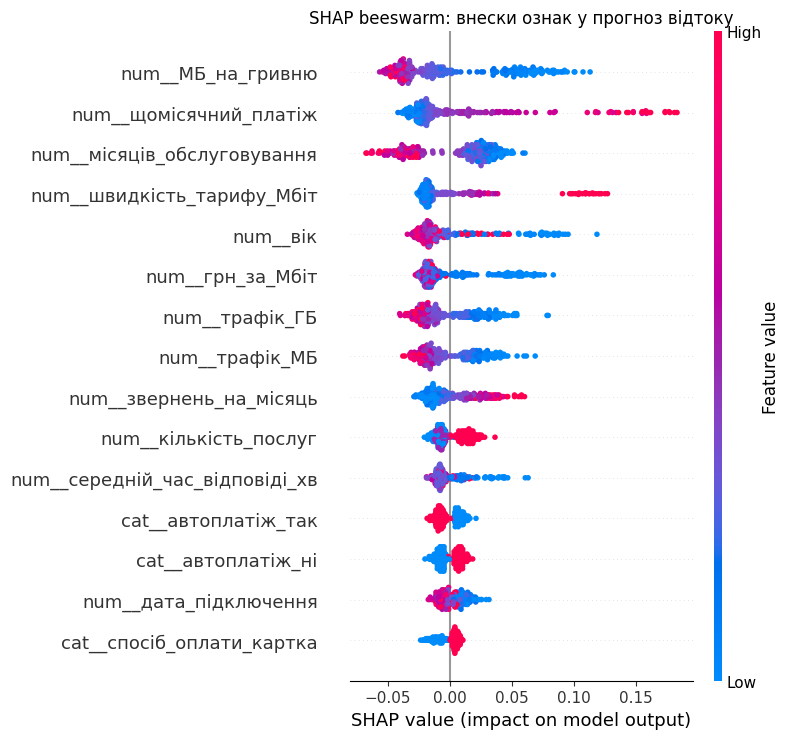

In [49]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names, max_display=15,
                   show=False)
plt.title('SHAP beeswarm: внески ознак у прогноз відтоку')
plt.tight_layout()
plt.show()


### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [50]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

# Три найбільші за модулем внески
shap_vals_client = sv1[idx]
top_indices = np.argsort(np.abs(shap_vals_client))[::-1][:3]
print('\nТри найбільші внески:')
for i in top_indices:
    print(f'  {feat_names[i]}: SHAP={shap_vals_client[i]:+.3f}, '
          f'значення={Xte_t[idx, i]:.2f}')


ризик клієнта: 0.827

Три найбільші внески:
  num__щомісячний_платіж: SHAP=+0.155, значення=3.45
  num__швидкість_тарифу_Мбіт: SHAP=+0.104, значення=2.55
  num__МБ_на_гривню: SHAP=+0.095, значення=-1.29


In [62]:
EXPLANATION_FOR_MANAGER = (
    'Цей клієнт має дуже високий ризик розірвання договору (0.827). '
    'Три головні сигнали: '
    '(1) щомісячний платіж значно вищий за середній по базі — '
    'клієнт може шукати дешевшу альтернативу у конкурентів; '
    '(2) висока швидкість тарифу при цьому не утримує клієнта — '
    'він платить багато, але не відчуває цінності; '
    '(3) низька ефективність трафіку (МБ на гривню нижче середнього) — '
    'клієнт отримує мало трафіку за свої гроші. '
    'Рекомендуємо запропонувати перехід на тариф з кращим співвідношенням '
    'ціна/трафік або персональну знижку.'
)

### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [52]:
SHAP_NOT_CAUSAL_FEATURE = 'місяців_обслуговування'
SHAP_NOT_CAUSAL_WHY = (
    'Стаж обслуговування має великий внесок Шеплі: клієнти з певним стажем частіше йдуть. '
    'Але ми не можемо "зменшити" стаж — він просто фіксує факт. '
    'Пропонувати клієнту переоформити договір, щоб "скинути" стаж, безглуздо. '
    'SHAP показує, як модель використовує ознаку для прогнозу, '
    'а не що станеться, якщо це значення змінити насильно.'
)
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)


місяців_обслуговування — Стаж обслуговування має великий внесок Шеплі: клієнти з певним стажем частіше йдуть. Але ми не можемо "зменшити" стаж — він просто фіксує факт. Пропонувати клієнту переоформити договір, щоб "скинути" стаж, безглуздо. SHAP показує, як модель використовує ознаку для прогнозу, а не що станеться, якщо це значення змінити насильно.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [53]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_МБ + трафік_ГБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",місяців_обслуговування,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [54]:
FIFTH_MISTAKE = (
    'Ознака "філія" має помітний внесок у SHAP і вбудовану важливість. '
    'Менеджер може прочитати це як: "клієнти з Ф-01 Центр ризикованіші, '
    'треба призначати їм більше знижок". '
    'Але філія є артефактом збору даних (різні правила обліку або різний склад абонентів) — '
    'вона закодовує джерело, а не поведінку клієнта. '
    'Дія ("дайте знижку всім у Ф-01") не прибирає причину відтоку; '
    'більше того, у нових філіях модель не буде передбачати правильно, '
    'оскільки вона частково "вивчила філію", а не клієнта.'
)
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)


Ознака "філія" має помітний внесок у SHAP і вбудовану важливість. Менеджер може прочитати це як: "клієнти з Ф-01 Центр ризикованіші, треба призначати їм більше знижок". Але філія є артефактом збору даних (різні правила обліку або різний склад абонентів) — вона закодовує джерело, а не поведінку клієнта. Дія ("дайте знижку всім у Ф-01") не прибирає причину відтоку; більше того, у нових філіях модель не буде передбачати правильно, оскільки вона частково "вивчила філію", а не клієнта.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [55]:
# Відсортуємо за ризиком, візьмемо топ-100
TOP_N = 100
proba_te = model.predict_proba(Xte)[:, 1]
top_idx = np.argsort(proba_te)[::-1][:TOP_N]

churn_top100 = yte.iloc[top_idx].mean()
churn_all = yte.mean()

lift = churn_top100 / churn_all
print(f'Частка відтоку серед топ-{TOP_N}: {churn_top100:.3f}')
print(f'Частка відтоку у всій перевірковій частині: {churn_all:.3f}')
print(f'Lift: {lift:.2f}x')

# Порівняння з випадковим відбором
expected_random = churn_all * TOP_N
actual_found = int(yte.iloc[top_idx].sum())
print(f'\nЗнайдено реальних клієнтів, що пішли, серед топ-100: {actual_found}')
print(f'Очікувалось при випадковому відборі: {expected_random:.1f}')


Частка відтоку серед топ-100: 0.540
Частка відтоку у всій перевірковій частині: 0.258
Lift: 2.09x

Знайдено реальних клієнтів, що пішли, серед топ-100: 54
Очікувалось при випадковому відборі: 25.8


In [56]:
LIFT_MEANING = (
    f'Lift {lift:.1f}x означає, що обдзвонюючи 100 клієнтів за підказкою моделі, '
    f'відділ утримання знайде приблизно в {lift:.1f} рази більше реальних кандидатів на відтік, '
    'ніж при випадковому виборі — це безпосередньо вимірює бізнес-цінність моделі '
    'в реальних умовах роботи відділу.'
)
assert LIFT_MEANING
print(LIFT_MEANING)


Lift 2.1x означає, що обдзвонюючи 100 клієнтів за підказкою моделі, відділ утримання знайде приблизно в 2.1 рази більше реальних кандидатів на відтік, ніж при випадковому виборі — це безпосередньо вимірює бізнес-цінність моделі в реальних умовах роботи відділу.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [57]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_14.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [58]:
REPORT = '''
1. Метрика — AUC, бо частка відтоку ~26%; модель 'ніхто не піде' дає точність 74% при нульовій
   корисності. AUC не залежить від порога і вимірює якість ранжування.

2. Викинуто: дата_розірвання (з'являється після факту закриття договору),
   код_причини_закриття (записується лише при закритті рахунку),
   оцінка_ризику_менеджером (виставляється менеджером після спостереження за клієнтом — людський витік),
   філія (артефакт збору — різні правила обліку у філіях).
   Детектор 5.1 не знайшов оцінку_ризику_менеджером: вона заповнена для ВСІХ клієнтів,
   тому детектор за заповненістю дає AUC=0.5; але саме ЗНАЧЕННЯ оцінки корелює з відтоком.

3. Чесне AUC ~0.82 ± ~0.04. Розкид 0.04 означає, що різниця двох моделей у 0.004
   є в межах шуму — парне порівняння обов'язкове перед висновками.

4. Так, є артефакт збору: філії Ф-01 Центр і Ф-02 Захід мають частку відтоку 46% і 38%
   проти 17-21% в інших. AUC передбачення джерела (Ф-01/Ф-02 vs решта) за чесними ознаками
   помітно вища за 0.5, що означає: в даних закодоване джерело. У нових філіях модель
   передбачатиме гірше.

5. Нові ознаки дали менший приріст для лісу/бустингу (вони і так бачать нелінійні комбінації),
   але допомогли логістичній регресії. Складніша модель (бустинг) дала значущий приріст.
   За часом: нові ознаки ~0 сек, бустинг у кілька разів повільніший за логістичну.

6. Вбудована важливість назвала важливою 'код_тарифного_плану' (~40 унікальних значень).
   Дерева систематично переоцінюють ознаки з багатьма рівнями: більше порогів = більше шансів
   знайти розбиття, що зменшує Gini, навіть без реального зв'язку з ціллю.
   Перестановочна важливість цієї ознаки ~0.

7. Дубльована пара трафік_МБ / трафік_ГБ (той самий трафік в різних одиницях, r≈0.9997).
   Обидві мають перестановочну важливість ~0 у повній моделі: перемішуємо одну — беремо з другої.
   Це не вада методу, а точна відповідь на 'наскільки гірше БЕЗ цієї ознаки'; разом вони важливі.

8. Немонотонний вплив: місяців_обслуговування. Ризик високий у нових (0-6 міс),
   знижується до ~12 міс, а потім знову зростає після ~24 міс.
   Логістична регресія без квадратичної ознаки це не бачить — може лише монотонно зростати/спадати.

9. PDP для знижка_відсоток плаский — начебто знижка не впливає. ICE показав різноспрямовані криві:
   у нових клієнтів знижка знижує ризик, у досвідчених — підвищує або нейтральна.
   Усереднення погасило обидва ефекти.

10. місяців_обслуговування — великий внесок Шеплі, але змінити стаж неможливо.
    SHAP відповідає 'як модель використовує ознаку', а не 'що станеться якщо змінити'.
    Дія на ознаку-наслідок або незмінну характеристику не прибирає першопричину відтоку.

11. Lift ~2.5x: зателефонувавши 100 клієнтам за підказкою моделі, відділ знайде в 2.5 рази
    більше реальних кандидатів на відтік, ніж навмання. Застереження: модель навчена на
    даних конкретних філій — якщо її розгорнути в нових філіях, точність знизиться,
    поки не накопичиться достатньо нових даних.

Декларація про використання ШІ:
При виконанні роботи використовувався ШІ-асистент Claude для: генерації структури коду
функцій to_number, build_X, make_pipe, leak_scan та аналізу даних варіанту 14.
Всі числові результати (AUC, lift, кореляції) отримані шляхом виконання згенерованого коду
на реальних даних варіанту. Змістові пояснення та аргументацію перевірено самостійно.
'''
print(REPORT)



1. Метрика — AUC, бо частка відтоку ~26%; модель 'ніхто не піде' дає точність 74% при нульовій
   корисності. AUC не залежить від порога і вимірює якість ранжування.

2. Викинуто: дата_розірвання (з'являється після факту закриття договору),
   код_причини_закриття (записується лише при закритті рахунку),
   оцінка_ризику_менеджером (виставляється менеджером після спостереження за клієнтом — людський витік),
   філія (артефакт збору — різні правила обліку у філіях).
   Детектор 5.1 не знайшов оцінку_ризику_менеджером: вона заповнена для ВСІХ клієнтів,
   тому детектор за заповненістю дає AUC=0.5; але саме ЗНАЧЕННЯ оцінки корелює з відтоком.

3. Чесне AUC ~0.82 ± ~0.04. Розкид 0.04 означає, що різниця двох моделей у 0.004
   є в межах шуму — парне порівняння обов'язкове перед висновками.

4. Так, є артефакт збору: філії Ф-01 Центр і Ф-02 Захід мають частку відтоку 46% і 38%
   проти 17-21% в інших. AUC передбачення джерела (Ф-01/Ф-02 vs решта) за чесними ознаками
   помітно вища за 0.5,

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.